## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


- 1. The point estimate of the ATE is -0.01. Thus, the proportion of patients receiving the invasive (pump) therapy survived 0.01 less than the proportion of patients receiving the conservative (non-invasive) therapy. Based on this, I would rather not get the intra aortic balloon pump and would opt for the more conservative therapy.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

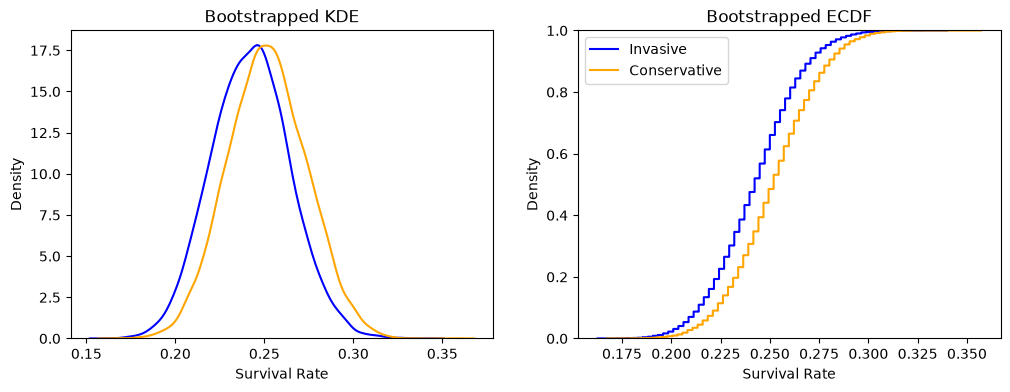

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

- 3. The shapes of the KDEs and ECDFs for the bootstrapped invasive and conservative treatment groups are very similar looking. Both KDEs roughly have a bell shape and they overlap a fair bit. This overlap conveys that across the 10,000 bootstrapped samples, the bootstrap estimates for one treatment is plausible for the other treatment. The peak survival rate for the invasive therapy is around 0.24 and the peak survival rate for the conservative therapy curve is around 0.25. Looking at the ECDFs, you can see that the invasive treatment is to the left of the conservative treatment at every value. Meaning, the survival rate of the invasive treatment is lower than the survival rate of the conservative treatment at every quantile.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

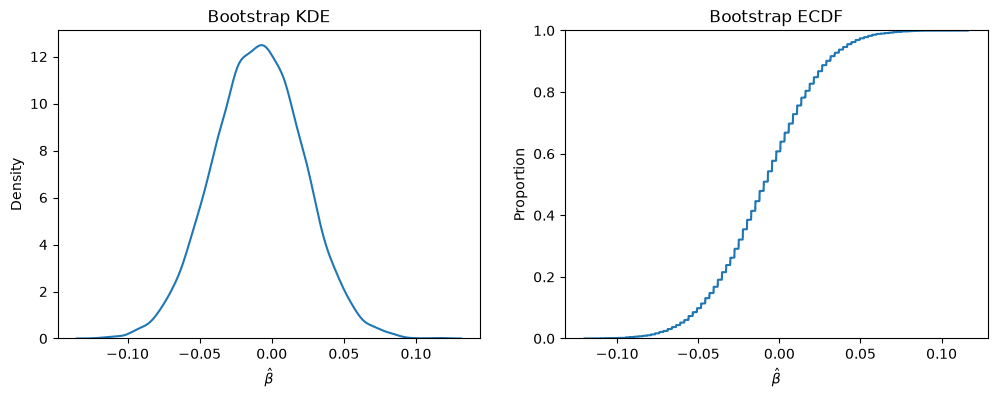

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


- 4. Yes, the KDE of the ATE has roughly a bell shape. The range of possible values for this intervention seem to be from around -0.10 to 0.10, and the peak of the curve (where the majority of the values landed) is around -0.01.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06111361  0.04180061]
95% CI: [-0.06889858  0.05208985]
99% CI: [-0.08946416  0.07266849]


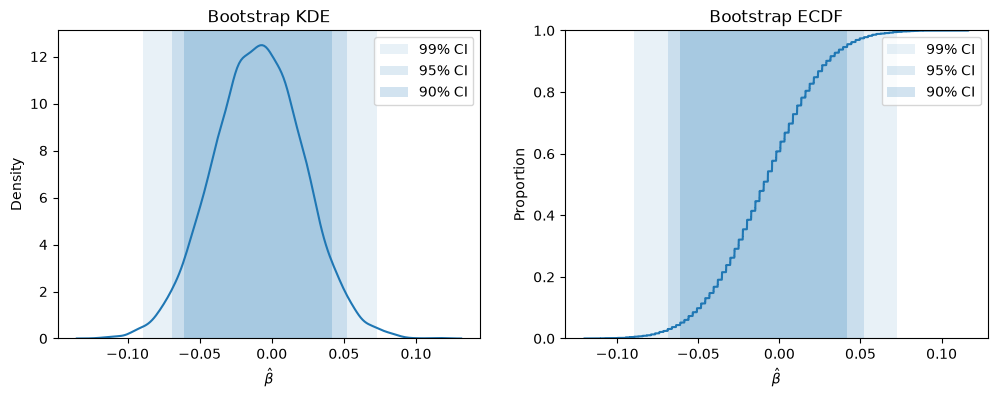

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

- 5.Yes, 0 is included in all three of the confidence intervals (90, 95, and 99). This evidence suggests that we would fail to reject the null hypothesis that the effect size is zero at every confidence interval (90, 95, and 99).

**6.** What have we learned about inserting balloons into hearts?

- 6. Based on this, we have learned that the evidence does not suggest any real difference in terms of survival rate for patients receiving the invasive (balloon pump) treatment compared to the more conservative treatment. While we cannot necessarily make any claim that the conservative approach is more effective, there seems to be no evidence that the invasive treatment would improve survival rate among patients. Therefore, it seems that adopting this invasive treatment would not be justified, especially given such high stakes.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

## 1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 

In [2]:
diabetes_df = pd.read_csv('./data/diabetes.csv')
diabetes_df.head()

,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success


In [3]:
## Crosstabs, average treatment effect:
print(pd.crosstab(diabetes_df['treatment'], diabetes_df['outcome']), '\n')

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 



In [4]:
# convert strings to integers for mean calcs
diabetes_df['outcome'] = diabetes_df['outcome'].replace({'success': 1,
                                                          'failure': 0})

In [5]:
# get average outcomes for each treatment group
ate_met_rosi = diabetes_df.loc[diabetes_df['treatment'] == 'met', 'outcome'].mean() \
    - diabetes_df.loc[diabetes_df['treatment'] == 'rosi', 'outcome'].mean()

ate_met_lifestyle = diabetes_df.loc[diabetes_df['treatment'] == 'met', 'outcome'].mean() \
    - diabetes_df.loc[diabetes_df['treatment'] == 'lifestyle', 'outcome'].mean()

ate_rosi_lifestyle = diabetes_df.loc[diabetes_df['treatment'] == 'rosi', 'outcome'].mean() \
    - diabetes_df.loc[diabetes_df['treatment'] == 'lifestyle', 'outcome'].mean()

print('Estimated ATE (Met versus Rosi):', np.round(ate_met_rosi, 3))
print('Estimated ATE (Met versus Lifestyle):', np.round(ate_met_lifestyle, 3))
print('Estimated ATE (Rosi versus Lifestyle):', np.round(ate_rosi_lifestyle, 3))

print(diabetes_df.groupby('treatment')['outcome'].mean().round(3)) #compute average outcome for each treatment group

Estimated ATE (Met versus Rosi): -0.131
Estimated ATE (Met versus Lifestyle): -0.051
Estimated ATE (Rosi versus Lifestyle): 0.08
treatment
lifestyle    0.534
met          0.483
rosi         0.614
Name: outcome, dtype: object


- 1. The average outcomes for the Lifestyle treatment group is 0.534, for Metformin it's 0.483, and for Rosiglitazone it is 0.614. The highest observed success rate is for Rosiglitazone and the lowest success rate is for Metformin. The estimated ATE (Met versus Rosi) is -0.131. The estimated ATE (Met versus Lifestyle) is -0.051, and the estimated ATE (Rosi versus Lifestyle) is 0.08.

## 2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 

In [7]:
# Bootstrapping:
R = 10_000

df_met = diabetes_df.loc[diabetes_df['treatment'] == 'met',:]
df_rosi = diabetes_df.loc[diabetes_df['treatment'] == 'rosi',:]
df_lifestyle = diabetes_df.loc[diabetes_df['treatment'] == 'lifestyle',:]

outcome_met = []
outcome_rosi = []
outcome_lifestyle = []

ate_met_rosi = [] # Store computed effects
ate_met_lifestyle = [] 
ate_rosi_lifestyle = []

for t in range(R):
    # Resample within each treatment arm
    df_mt = df_met.sample(frac=1.0, replace=True)
    df_rt = df_rosi.sample(frac=1.0, replace=True)
    df_lt = df_lifestyle.sample(frac=1.0, replace=True)

    # Evaluate outcomes:
    omet = df_mt['outcome'].mean() # Mean outcome for met
    orosi = df_rt['outcome'].mean() # Mean outcome for rosi
    olifestyle = df_lt['outcome'].mean() # Mean outcome for lifestyle

    # Compute ATE:
    ate_met_rosi.append(omet - orosi)
    ate_met_lifestyle.append(omet - olifestyle)
    ate_rosi_lifestyle.append(orosi - olifestyle)

    # Store results:
    outcome_met.append(omet) # Save new value
    outcome_rosi.append(orosi) # Save new value
    outcome_lifestyle.append(olifestyle) # Save new value

## 3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.

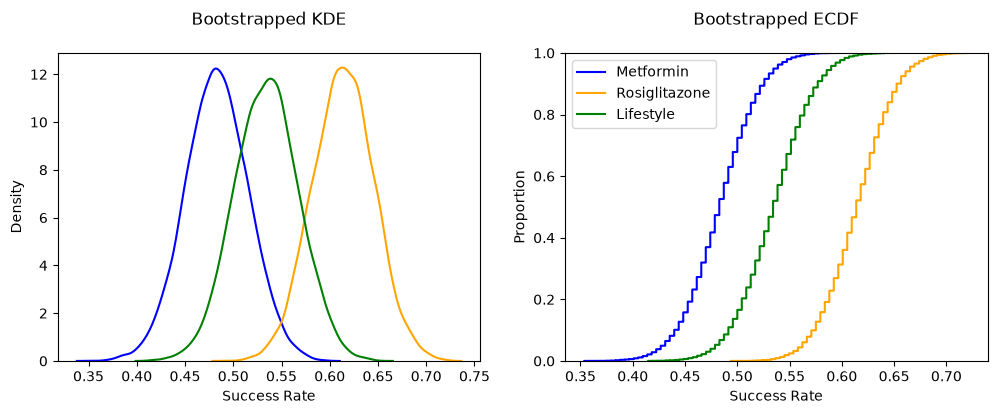

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='Metformin', color='blue', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')
sns.kdeplot(outcome_lifestyle, label='Lifestyle', color='green', ax=ax[0]).set(title='Bootstrapped KDE\n', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_met, label='Metformin', color='blue', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')
sns.ecdfplot(outcome_lifestyle, label='Lifestyle', color='green', ax=ax[1]).set(title='Bootstrapped ECDF\n', xlabel='Success Rate', ylabel='Proportion')

plt.legend()
plt.show()

- 3. The Bootstrapped KDEs and ECDFs appear to have similar distribution shape and the spread also looks similar. Looking at the densities, I notice that the Rosiglitazone has the least amount of overlap with the other two treatment curves and is centered about a higher value, centered around 0.61 (success rate) compared to the other two curves (with the Metformin curve centered around approximately 0.48 and the Lifestyle curve centered approximately around 0.54). None of the ECDFs curve cross, and the Metformin and the Rosiglitazone curves are the farthest apart. The median of the ECDFs shows that the typical success rate is lowest for Metformin, then Lifestyle, and then the Rosiglitazone intervention.

## 4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.

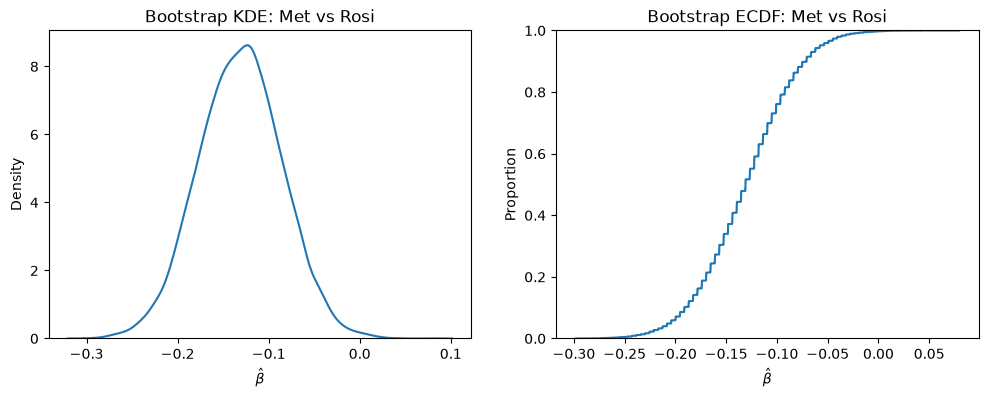

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDE for Met vs Rosi
sns.kdeplot(ate_met_rosi, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE: Met vs Rosi")

# ECDF for Met vs Rosi
sns.ecdfplot(ate_met_rosi, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF: Met vs Rosi")

plt.show()

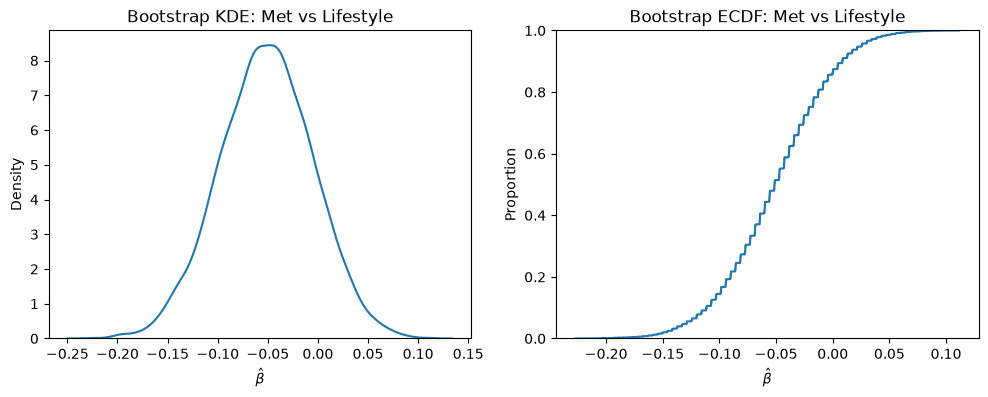

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDE for Met vs Lifestyle
sns.kdeplot(ate_met_lifestyle, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE: Met vs Lifestyle")

# ECDF for Met vs Lifestyle
sns.ecdfplot(ate_met_lifestyle, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF: Met vs Lifestyle")

plt.show()

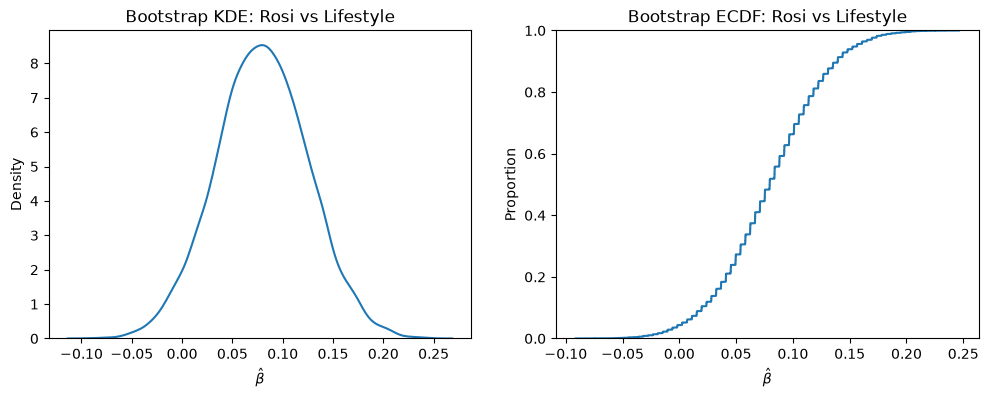

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDE for Rosi vs Lifestyle
sns.kdeplot(ate_rosi_lifestyle, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE: Rosi vs Lifestyle")

# ECDF for Rosi vs Lifestyle
sns.ecdfplot(ate_rosi_lifestyle, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF: Rosi vs Lifestyle")

plt.show()

## 5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

In [12]:
ci90_ate_met_rosi = np.quantile(ate_met_rosi, [.05, .95])
ci95_ate_met_rosi = np.quantile(ate_met_rosi, [.025, .975])
ci99_ate_met_rosi = np.quantile(ate_met_rosi, [.005, .995])

print(f"90% CI (Met vs Rosi): {ci90_ate_met_rosi}")
print(f"95% CI (Met vs Rosi): {ci95_ate_met_rosi}")
print(f"99% CI (Met vs Rosi): {ci99_ate_met_rosi}")

ci90_ate_met_lifestyle = np.quantile(ate_met_lifestyle, [.05, .95])
ci95_ate_met_lifestyle = np.quantile(ate_met_lifestyle, [.025, .975])
ci99_ate_met_lifestyle = np.quantile(ate_met_lifestyle, [.005, .995])

print(f"90% CI (Met vs Lifestyle): {ci90_ate_met_lifestyle}")
print(f"95% CI (Met vs Lifestyle): {ci95_ate_met_lifestyle}")
print(f"99% CI (Met vs Lifestyle): {ci99_ate_met_lifestyle}")

ci90_ate_rosi_lifestyle = np.quantile(ate_rosi_lifestyle, [.05, .95])
ci95_ate_rosi_lifestyle = np.quantile(ate_rosi_lifestyle, [.025, .975])
ci99_ate_rosi_lifestyle = np.quantile(ate_rosi_lifestyle, [.005, .995])

print(f"90% CI (Rosi vs Lifestyle): {ci90_ate_rosi_lifestyle}")
print(f"95% CI (Rosi vs Lifestyle): {ci95_ate_rosi_lifestyle}")
print(f"99% CI (Rosi vs Lifestyle): {ci99_ate_rosi_lifestyle}")

90% CI (Met vs Rosi): [-0.20417807 -0.05775492]
95% CI (Met vs Rosi): [-0.221308   -0.04075403]
99% CI (Met vs Rosi): [-0.25125814 -0.01052603]
90% CI (Met vs Lifestyle): [-0.12875774  0.02567787]
95% CI (Met vs Lifestyle): [-0.14217967  0.0386089 ]
99% CI (Met vs Lifestyle): [-0.17573    0.0647097]
90% CI (Rosi vs Lifestyle): [0.00251183 0.15656065]
95% CI (Rosi vs Lifestyle): [-0.01039947  0.16954624]
99% CI (Rosi vs Lifestyle): [-0.0361322   0.19953432]


- 5. Looking at the computed confidence intervals for each pairwise ATE, there appears to be statistically significant differences between Metformin versus Rosiglitazone at the 90, 95, and 99% confidence level. There also appears to be a statistically significant difference for Rosiglitazone versus Lifestyle only at the 90% confidence level ([0.00671289 0.15245222]), but not at the 95 and 99% confidence level, since those confidence intervals contain 0, so the evidence is suggestive but not incredibly strong. It doesn't look like there is a statistically significant difference for Metformin versus Lifestyle at any of the 90, 95, and 99 confidence levels. Based on this evidence, the most effective treatment (based on the success rate) seems to be Rosiglitazone. There is strong evidence that it is has a higher success rate than Metformin, though it is not entirely conclusive that there is clear advantage between Rosiglitazone and the lifestyle treatment.

## 6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

- Report PDF is added to the repo in the Thursday Lab folder.

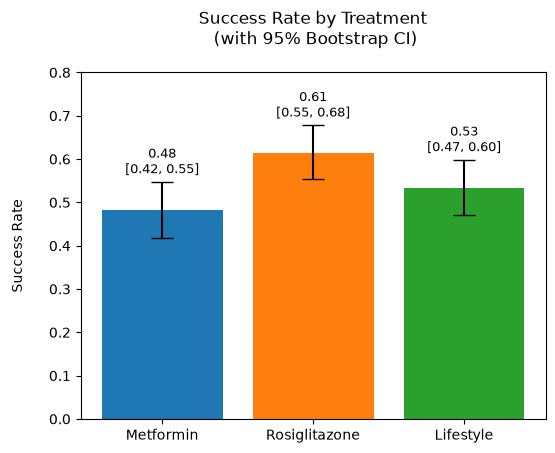

In [23]:
rates = diabetes_df.groupby('treatment')['outcome'].mean().reindex(['met', 'rosi', 'lifestyle'])
arm_boots = [outcome_met, outcome_rosi, outcome_lifestyle]
arm_labels = ['Metformin', 'Rosiglitazone', 'Lifestyle']

lo = np.array([np.quantile(b, .025) for b in arm_boots])
hi = np.array([np.quantile(b, .975) for b in arm_boots])
yerr = [rates.values - lo, hi - rates.values]

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(arm_labels, rates.values, color=['tab:blue', 'tab:orange', 'tab:green'],
       yerr=yerr, capsize=8, error_kw={'elinewidth': 1.5})

for i in range(3):
    ax.text(i, hi[i] + 0.02, f"{rates.values[i]:.2f}\n[{lo[i]:.2f}, {hi[i]:.2f}]",
           ha='center', fontsize=9)

ax.set_ylabel("Success Rate\n")
ax.set_title("Success Rate by Treatment\n (with 95% Bootstrap CI)\n")
ax.set_ylim(0, 0.8)
plt.show()

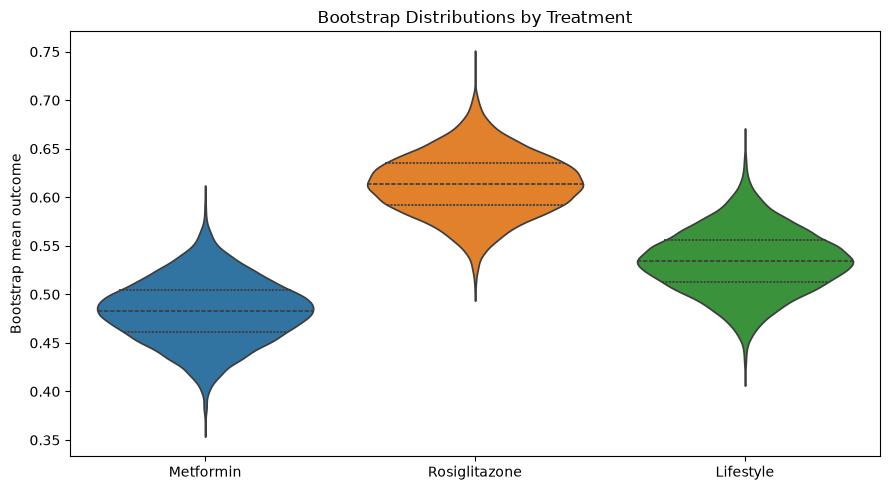

In [34]:
bootstrap_outcomes = pd.DataFrame({
    'Metformin': outcome_met,
    'Rosiglitazone': outcome_rosi,
    'Lifestyle': outcome_lifestyle
})

plt.figure(figsize=(9, 5))
sns.violinplot(data=bootstrap_outcomes, inner='quartile', cut=0)
plt.ylabel('Bootstrap mean outcome')
plt.title('Bootstrap Distributions by Treatment')
plt.tight_layout()
plt.show()

Note: Generative AI was used to help with the creation process of the plots.